In [1]:
import torch
from torchvision import datasets

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 42.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.12MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.31MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.03MB/s]


In [2]:
print(len(train_data))

60000


In [5]:
image, label = train_data[0]

print(image)
print(label)

<PIL.Image.Image image mode=L size=28x28 at 0x7FA420605A50>
5


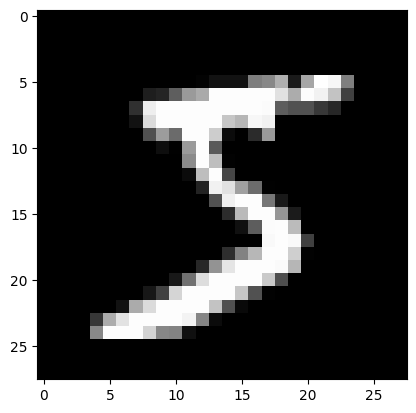

In [6]:
import matplotlib.pyplot as plt

plt.imshow(image, cmap="gray")
plt.show()

In [7]:
print(len(train_data))
print(train_data[0])

60000
(<PIL.Image.Image image mode=L size=28x28 at 0x7FA4205F7A00>, 5)


In [9]:
import torch
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

In [10]:
image, label = train_data[0]

print(image)
print(label)

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

In [11]:
print(image.shape)

torch.Size([1, 28, 28])


[채널 수, 높이, 넓이]

In [12]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

In [13]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([64, 1, 28, 28])
torch.Size([64])


완전 연결 신경망

In [14]:
import torch.nn as nn

In [18]:
class SimpleNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc = nn.Linear(28 * 28, 10) # 0-9까지 판단

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        x = self.fc(x)
        return x

In [19]:
model = SimpleNN()

images, labels = next(iter(train_loader))

outputs = model(images)

print(outputs.shape)

torch.Size([64, 10])


In [34]:
loss_fn = nn.CrossEntropyLoss()

loss = loss_fn(outputs, labels)

print(loss)

tensor(1.5008, grad_fn=<NllLossBackward0>)


In [22]:
import torch.optim as optim

optimizer = optim.SGD(model.parameters(), lr=0.01)

optimizer.zero_grad()

loss.backward()

optimizer.step()

In [32]:
for i in range(10):
    optimizer.zero_grad()

    outputs = model(images)
    loss = loss_fn(outputs, labels)

    loss.backward()
    optimizer.step()

    print(i + 1, loss.item())

1 1.5868933200836182
2 1.5769410133361816
3 1.567089319229126
4 1.557336688041687
5 1.5476818084716797
6 1.5381234884262085
7 1.528659701347351
8 1.5192897319793701
9 1.5100120306015015
10 1.5008256435394287


In [33]:
predictions = torch.argmax(outputs, dim=1)

print("예측:", predictions[:10])
print("정답:", labels[:10])

예측: tensor([5, 1, 2, 9, 9, 1, 1, 7, 9, 1])
정답: tensor([5, 6, 0, 9, 4, 8, 8, 7, 9, 1])


In [35]:
for epoch in range(3):
    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

    print(f"Epoch {epoch + 1}, Loss: {loss.item():.4f}")

Epoch 1, Loss: 0.6431
Epoch 2, Loss: 0.4573
Epoch 3, Loss: 0.3050


In [38]:
test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)

In [39]:
correct = 0
total = 0

for images, labels in test_loader:
    outputs = model(images)
    predictions = torch.argmax(outputs, dim=1)

    correct += (predictions == labels).sum().item()
    total += labels.size(0)

accuracy = correct / total

print(f"정확도: {accuracy * 100:.2f}%")

정확도: 89.09%


In [40]:
class BetterNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        x = self.fc1(x)
        x = torch.relu(x)
        x = self.fc2(x)
        return x

In [41]:
model = BetterNN()

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [42]:
for epoch in range(3):
    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

    print(f"Epoch {epoch + 1}, Loss: {loss.item():.4f}")

Epoch 1, Loss: 0.0679
Epoch 2, Loss: 0.0918
Epoch 3, Loss: 0.0733


In [43]:
correct = 0
total = 0

for images, labels in test_loader:
    outputs = model(images)
    predictions = torch.argmax(outputs, dim=1)

    correct += (predictions == labels).sum().item()
    total += labels.size(0)

accuracy = correct / total

print(f"정확도: {accuracy * 100:.2f}%")

정확도: 97.02%
